## Evaluate the performance of a neural network using different metrics

code to evaluate the performance of a neural network using different metrics such as:

1. Accuracy

2. Precision

3. Recall

4. F1-Score

5. Confusion Matrix

6. ROC Curve & AUC

7. Loss/Accuracy curves

### 1. Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### 2. Load and Preprocess the Dataset

In [7]:
data = load_iris()
X = data.data
y = data.target.reshape(-1, 1)

# One-hot encode labels
encoder = OneHotEncoder(sparse=False)
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# Normalize input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 3. Build the Neural Network

In [8]:
model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(12, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                80        
                                                                 
 dense_1 (Dense)             (None, 12)                204       
                                                                 
 dense_2 (Dense)             (None, 3)                 39        
                                                                 
Total params: 323
Trainable params: 323
Non-trainable params: 0
_________________________________________________________________


### 4. Train the Model

In [10]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
11/11 [==============================] - 0s 16ms/step - loss: 0.1392 - accuracy: 0.9643 - val_loss: 0.2101 - val_accuracy: 0.9524
Epoch 2/50
11/11 [==============================] - 0s 11ms/step - loss: 0.1365 - accuracy: 0.9524 - val_loss: 0.2126 - val_accuracy: 0.9524
Epoch 3/50
11/11 [==============================] - 0s 11ms/step - loss: 0.1344 - accuracy: 0.9643 - val_loss: 0.2033 - val_accuracy: 0.9524
Epoch 4/50
11/11 [==============================] - 0s 10ms/step - loss: 0.1329 - accuracy: 0.9643 - val_loss: 0.1957 - val_accuracy: 0.9524
Epoch 5/50
11/11 [==============================] - 0s 9ms/step - loss: 0.1302 - accuracy: 0.9643 - val_loss: 0.2013 - val_accuracy: 0.9524
Epoch 6/50
11/11 [==============================] - 0s 10ms/step - loss: 0.1261 - accuracy: 0.9643 - val_loss: 0.1945 - val_accuracy: 0.9524
Epoch 7/50
11/11 [==============================] - 0s 10ms/step - loss: 0.1241 - accuracy: 0.9643 - val_loss: 0.1899 - val_accuracy: 0.9524
Epoch 8/50
11/

### 5. Evaluate on Test Data

In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.03516190126538277
Test Accuracy: 1.0


### 6. Predictions & Metrics

In [12]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)


2/2 [==============================] - 0s 6ms/step

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


### 7. ROC Curve & AUC (One-vs-Rest)


Overall AUC Score: 1.0


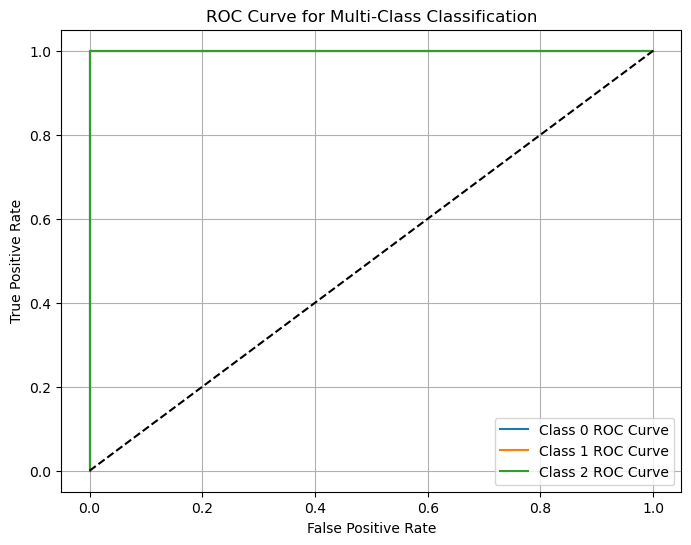

In [13]:
auc_score = roc_auc_score(y_test, y_pred_prob, multi_class='ovr')
print("\nOverall AUC Score:", auc_score)

# Plot ROC Curves
plt.figure(figsize=(8, 6))

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test[:, i], y_pred_prob[:, i])
    plt.plot(fpr, tpr, label=f"Class {i} ROC Curve")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Multi-Class Classification")
plt.legend()
plt.grid(True)
plt.show()

### 8. Plot Training Curves

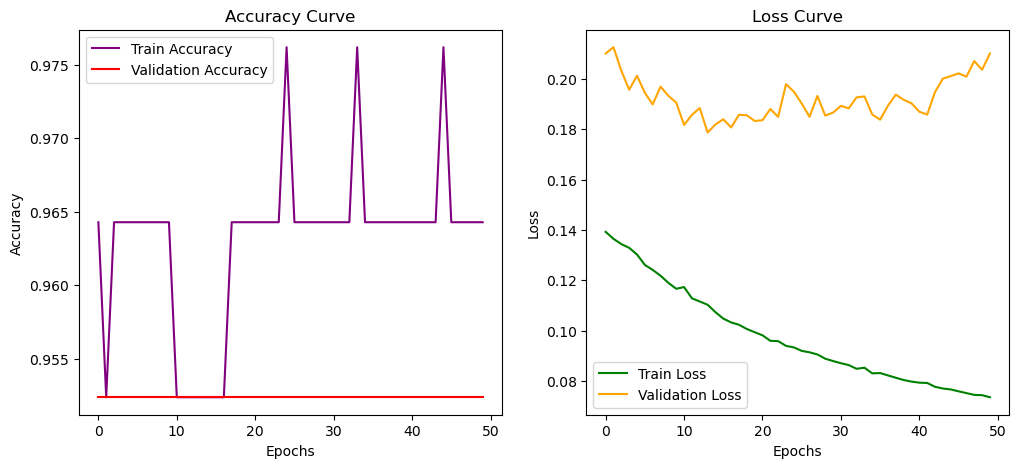

In [17]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label="Train Accuracy", color="purple")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy", color="red")
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label="Train Loss", color="Green")
plt.plot(history.history['val_loss'], label="Validation Loss", color="orange")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()